# Лабораторная работа № 5

**Тема:** Метрики качества, baseline-прогнозы и стратегии валидации временных рядов

**Цель:** сравнить простые методы прогнозирования на одном временном ряду, оценить качество разными метриками, выполнить backtesting без утечки будущих данных и исследовать интервальные прогнозы

**Задачи:** 
1. создать ряд с помощью генератора из лабораторной № 1
2. реализовать Naive, Seasonal Naive, Mean, Drift, Theta
3. выполнить expanding/sliding backtesting
4. рассчитать MAE, RMSE, MAPE, sMAPE, MASE
5. оценить интервалы через coverage/width
6. показать опасность случайного разбиения и сформулировать выводы

## 1. Подключение библиотек и оформление

`NumPy` необходим для вычислений, `pandas` - для временного индекса и таблиц, `matplotlib` - для графиков. `ThetaModel` из `statsmodels` реализует метод Theta

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.forecasting.theta import ThetaModel

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

PURPLE = "#7E57C2"
DARK = "#512DA8"
LILAC = "#B39DDB"
PINK = "#CE93D8"
LIGHT = "#E1BEE7"

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.20,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

def save_plot(number):
    plt.tight_layout()
    plt.savefig(IMAGE_DIR / f"lab_image_{number}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 2. Использование генератора из лабораторной № 1

Ниже приведена **та же функция `generate_time_series()`**, что и в первой лабораторной. Мы не заменяем её другим генератором. Она создаёт данные каждые 5 минут, а затем мы преобразуем их в дневные значения и добавляем недельные колебания, необходимые для задания

In [ ]:
from datetime import datetime, timedelta

"""Возвращает метки времени, значения ряда и выбранные режимы"""
def generate_time_series(n_points=1000, volatility="random", trend="random",
                         seasonality="random", seed=None):
    if not isinstance(n_points, (int, np.integer)) or isinstance(n_points, (bool, np.bool_)) or n_points <= 0:
        raise ValueError("n_points должно быть положительным целым числом")

    volatility_modes = ("const", "grow", "decay")
    trend_modes = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
    seasonality_modes = ("none", "one", "two")

    for label, option, modes in (
        ("volatility", volatility, volatility_modes),
        ("trend", trend, trend_modes),
        ("seasonality", seasonality, seasonality_modes),
    ):
        if option not in (*modes, "random"):
            raise ValueError(f"Недопустимое значение {label}: {option}. Допустимые: {(*modes, 'random')}")

    rng = np.random.default_rng(seed)
    if volatility == "random":
        volatility = str(rng.choice(volatility_modes))
    if trend == "random":
        trend = str(rng.choice(trend_modes))
    if seasonality == "random":
        seasonality = str(rng.choice(seasonality_modes))

    start_time = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    t = np.arange(n_points)
    position = t / max(n_points - 1, 1)  # от 0 до 1 на протяжении ряда

    # Тренд: изменения за весь наблюдаемый отрезок
    total_changes = {"none": 0, "fast_up": 35, "slow_up": 10,
                     "fast_down": -35, "slow_down": -10}
    trend_values = total_changes[trend] * position

    # Сезонность: периоды 12 точек (1 час) и 72 точки (6 часов)
    seasonal_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        seasonal_values += 7 * np.sin(2 * np.pi * t / 12)
    if seasonality == "two":
        seasonal_values += 4 * np.sin(2 * np.pi * t / 72)

    # Стандартное отклонение задаёт силу шума; дисперсия равна его квадрату.
    if volatility == "const":
        sigma = np.full(n_points, 2.0)
    elif volatility == "grow":
        sigma = 1.0 + 6.0 * position
    else:  # decay
        sigma = 7.0 - 6.0 * position

    noise = rng.normal(loc=0.0, scale=sigma, size=n_points)
    values = 100.0 + trend_values + seasonal_values + noise
    modes = {"volatility": volatility, "trend": trend, "seasonality": seasonality}
    return timestamps, values, modes

: 

## 3. Подготовка данных и визуальный анализ

Генерируем **140 суток**: $140\cdot 24\cdot12=40320$ пятиминутных точек. Каждые 288 значений усредняем в один дневной показатель. К дневному ряду добавляем недельную сезонность и небольшой случайный шум (имитация дневных изменений)

Для прогнозирования выбираем **горизонт $H=7$ суток**: модель прогнозирует следующую неделю. Сезонный период $s=7$ означает повторение недельного цикла. Все случайные значения воспроизводимы благодаря `seed`

Дневных значений: 140
Начало: 2026-11-23 Конец: 2027-04-11
Период сезонности: 7 дней


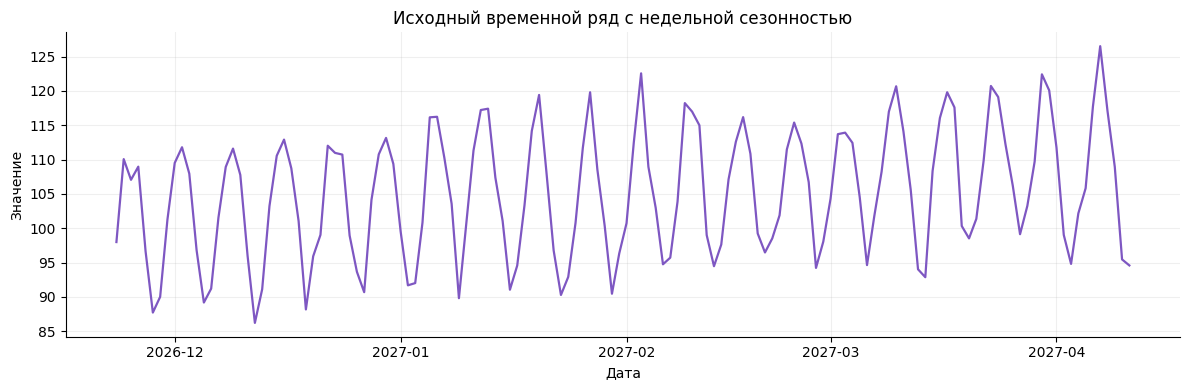

In [3]:
DAYS = 140
H = 7
S = 7

# Один день содержит 24 * 12 пятиминутных измерений
timestamps, values, modes = generate_time_series(
    n_points=DAYS * 24 * 12,
    volatility="const",
    trend="slow_up",
    seasonality="none",
    seed=42
)

five_minute = pd.Series(values, index=pd.to_datetime(timestamps), name="value")
daily = five_minute.resample("D").mean()

rng = np.random.default_rng(2026)
t = np.arange(len(daily))
weekly = 12 * np.sin(2 * np.pi * t / S)
daily = daily + weekly + rng.normal(0, 2.5, len(daily))
daily.name = "value"

daily.to_frame().to_csv("series.csv", index_label="timestamp")
print("Дневных значений:", len(daily))
print("Начало:", daily.index[0].date(), "Конец:", daily.index[-1].date())
print("Период сезонности:", S, "дней")

plt.plot(daily.index, daily, color=PURPLE, linewidth=1.6)
plt.title("Исходный временной ряд с недельной сезонностью")
plt.ylabel("Значение")
plt.xlabel("Дата")
save_plot(1)

## 4. Пять baseline-моделей

**Baseline** - простой прогноз, с которым сравнивают более сложные методы

- **Naive:** все будущие значения равны последнему известному
- **Seasonal Naive:** повторяем предыдущую неделю. Для горизонта 7 и сезонного периода 7 используем семь последних значений обучения
- **Mean:** каждое будущее значение равно среднему обучающей части
- **Drift:** продолжаем наклон прямой между первым и последним значениями обучения
- **Theta:** метод из `statsmodels`, сочетающий сглаживание и тенденцию. Для корректности на каждом шаге подбирается **только по обучающей части**

Важно: прогноз строится сразу на семь шагов, не используя реальные значения тестовой недели

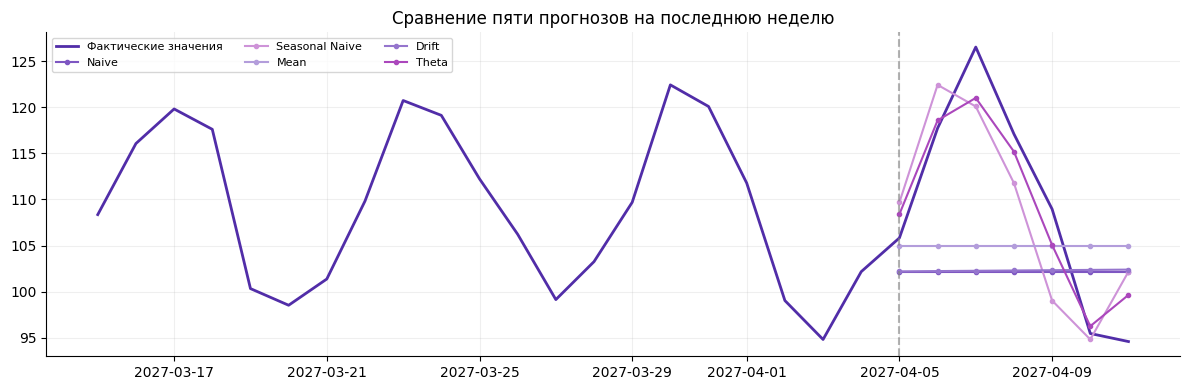

In [4]:
def forecast_naive(train, horizon):
    return np.repeat(train[-1], horizon)


def forecast_seasonal_naive(train, horizon, season=7):
    return np.resize(train[-season:], horizon)


def forecast_mean(train, horizon):
    return np.repeat(np.mean(train), horizon)


def forecast_drift(train, horizon):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, horizon + 1)


def forecast_theta(train, horizon):
    # Параметр period=7 соответствует недельной сезонности
    model = ThetaModel(train, period=7, deseasonalize=True)
    fitted = model.fit()
    return np.asarray(fitted.forecast(horizon))


models = {
    "Naive": forecast_naive,
    "Seasonal Naive": forecast_seasonal_naive,
    "Mean": forecast_mean,
    "Drift": forecast_drift,
    "Theta": forecast_theta,
}

# Демонстрация прогноза на последнюю неделю
train_demo = daily.to_numpy()[:-H]
actual_demo = daily.to_numpy()[-H:]
forecast_demo = {name: fn(train_demo, H) for name, fn in models.items()}

plt.plot(daily.index[-28:], daily.iloc[-28:], color=DARK, label="Фактические значения", linewidth=2)
for name, color in zip(models, [PURPLE, PINK, LILAC, "#9575CD", "#AB47BC"]):
    plt.plot(daily.index[-H:], forecast_demo[name], marker="o", ms=3, label=name, color=color)
plt.axvline(daily.index[-H], color="gray", linestyle="--", alpha=0.6)
plt.title("Сравнение пяти прогнозов на последнюю неделю")
plt.legend(ncol=3, fontsize=8)
save_plot(2)

## 5. Метрики качества прогноза

Пусть $y_i$ - фактическое значение, $\hat y_i$ - прогноз, $n$ - число прогнозов

**MAE** - средняя абсолютная ошибка:
$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|$$

**RMSE** - корень из средней квадратичной ошибки (сильнее реагирует на большие промахи):
$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}$$

**MAPE** - средняя процентная ошибка (нельзя применять при фактических нулях):
$$\mathrm{MAPE}=\frac{100}{n}\sum_{i=1}^{n}\left|\frac{y_i-\hat y_i}{y_i}\right|$$

**sMAPE** - симметризованная процентная ошибка:
$$\mathrm{sMAPE}=\frac{100}{n}\sum_{i=1}^{n}\frac{2|y_i-\hat y_i|}{|y_i|+|\hat y_i|}$$

**MASE** - MAE, делённая на среднюю ошибку сезонного Naive **только на обучении**:
$$\mathrm{MASE}=\frac{\mathrm{MAE}_{test}}{\frac{1}{T-s}\sum_{t=s+1}^{T}|y_t-y_{t-s}|},\quad s=7$$

In [5]:
def calculate_metrics(actual, predicted, train, season=7):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    train = np.asarray(train, dtype=float)
    error = actual - predicted

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # Не делим на ноль при расчёте процентной ошибки
    mape = 100 * np.mean(np.abs(error / actual)) if np.all(actual != 0) else np.nan
    denominator = np.abs(actual) + np.abs(predicted)
    smape = 100 * np.mean(np.divide(2 * np.abs(error), denominator,
                                    out=np.zeros_like(error), where=denominator != 0))

    seasonal_scale = np.mean(np.abs(train[season:] - train[:-season]))
    mase = mae / seasonal_scale if seasonal_scale > 0 else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape,
            "sMAPE": smape, "MASE": mase}

## 6. Backtesting: expanding и sliding window

Выполняем **10 последовательных прогнозов** с горизонтом 7 дней

- **Expanding:** сначала обучаемся на первых 70 днях, затем каждый раз добавляем новую неделю в историю
- **Sliding:** используем только последние 28 дней (4 недельных сезона), окно передвигается вперёд

Тестовая неделя всегда находится **после** обучающей. Все модели оцениваются на одних и тех же датах, информация из будущего не используется

На каждом шаге отдельно считаем метрики. Затем усредняем их по десяти шагам. Это позволяет сравнить не только типичную ошибку, но и её изменчивость

In [6]:
def backtesting(series, scheme="expanding", horizon=7, initial_train=70, window=28, steps=10):
    values = np.asarray(series, dtype=float)
    rows = []
    forecasts = []

    for fold in range(steps):
        cutoff = initial_train + fold * horizon
        train_start = 0 if scheme == "expanding" else cutoff - window
        train = values[train_start:cutoff]
        actual = values[cutoff:cutoff + horizon]
        assert len(actual) == horizon

        for name, model in models.items():
            prediction = model(train, horizon)
            metrics = calculate_metrics(actual, prediction, train, season=S)
            rows.append({"Схема": scheme, "Шаг": fold + 1, "Модель": name, **metrics})
            for h, (fact, pred) in enumerate(zip(actual, prediction), start=1):
                forecasts.append({"Схема": scheme, "Шаг": fold + 1,
                                  "Модель": name, "Горизонт": h,
                                  "Факт": fact, "Прогноз": pred})
    return pd.DataFrame(rows), pd.DataFrame(forecasts)


expanding_results, expanding_forecasts = backtesting(daily, scheme="expanding")
sliding_results, sliding_forecasts = backtesting(daily, scheme="sliding")

fold_results = pd.concat([expanding_results, sliding_results], ignore_index=True)
all_forecasts = pd.concat([expanding_forecasts, sliding_forecasts], ignore_index=True)

comparison = (fold_results.groupby(["Схема", "Модель"])[["MAE", "RMSE", "MAPE", "sMAPE", "MASE"]]
              .mean().round(4))
comparison.to_csv("comparison.csv")
fold_results.to_csv("backtesting_folds.csv", index=False)
all_forecasts.to_csv("forecasts.csv", index=False)
print(comparison.to_string())

                              MAE     RMSE    MAPE    sMAPE    MASE
Схема     Модель                                                   
expanding Drift           10.3986  12.4464  9.2754   9.8666  4.0925
          Mean             8.0470   9.3926  7.3140   7.5074  3.1653
          Naive           10.3756  12.4361  9.2503   9.8420  4.0834
          Seasonal Naive   3.0166   3.7427  2.8207   2.8294  1.1865
          Theta            2.5472   2.9703  2.3889   2.3842  0.9998
sliding   Drift           10.8914  12.9079  9.7221  10.3891  4.0953
          Mean             7.6714   8.7509  7.1231   7.1527  2.8768
          Naive           10.3756  12.4361  9.2503   9.8420  3.8854
          Seasonal Naive   3.0166   3.7427  2.8207   2.8294  1.1427
          Theta            3.3818   3.8514  3.1312   3.1501  1.2622


## 7. Сравнение точности и устойчивости

Для каждой схемы сравниваем пять моделей по MASE, MAE и RMSE. Отдельно рассматриваем разброс MAE между шагами: **меньшее стандартное отклонение** означает более стабильную ошибку на разных неделях. Но стабильность и точность - разные свойства

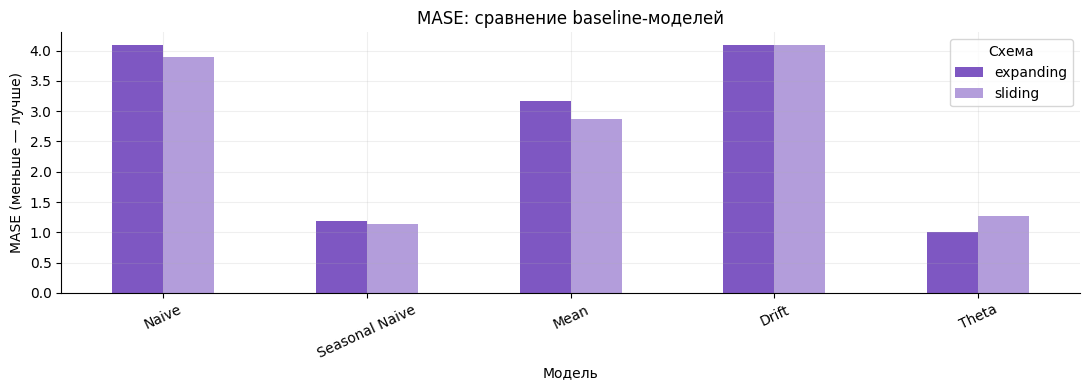

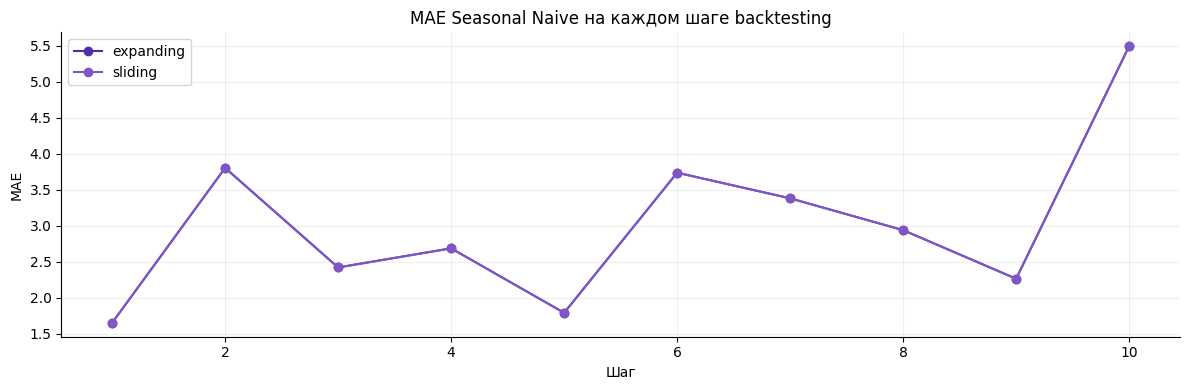

                          Средняя MAE  Стандартное отклонение MAE
Схема     Модель                                                 
expanding Drift               10.3986                      2.2485
          Mean                 8.0470                      1.3181
          Naive               10.3756                      2.1940
          Seasonal Naive       3.0166                      1.1456
          Theta                2.5472                      0.4273
sliding   Drift               10.8914                      2.8508
          Mean                 7.6714                      1.1640
          Naive               10.3756                      2.1940
          Seasonal Naive       3.0166                      1.1456
          Theta                3.3818                      1.5970


In [7]:
# Средние значения MASE для пяти моделей в двух схемах
mase_table = comparison["MASE"].unstack("Схема").loc[list(models)]
ax = mase_table.plot(kind="bar", color=[PURPLE, LILAC], figsize=(11, 4), rot=25)
ax.set_title("MASE: сравнение baseline-моделей")
ax.set_ylabel("MASE (меньше — лучше)")
ax.set_xlabel("Модель")
ax.legend(title="Схема")
save_plot(3)

# Ошибки на каждой неделе: так видно устойчивость разных схем
stable = fold_results[fold_results["Модель"] == "Seasonal Naive"]
for scheme, color in [("expanding", DARK), ("sliding", PURPLE)]:
    subset = stable[stable["Схема"] == scheme]
    plt.plot(subset["Шаг"], subset["MAE"], marker="o", color=color, label=scheme)
plt.title("MAE Seasonal Naive на каждом шаге backtesting")
plt.xlabel("Шаг")
plt.ylabel("MAE")
plt.legend()
save_plot(4)

stability = (fold_results.groupby(["Схема", "Модель"])["MAE"]
             .agg(["mean", "std"]).round(4))
stability.columns = ["Средняя MAE", "Стандартное отклонение MAE"]
print(stability.to_string())

## 8. Интервальный прогноз Seasonal Naive

Точечный прогноз показывает одно число. Интервальный прогноз задаёт диапазон возможных значений. Построим **90% эмпирический интервал** по ошибкам Seasonal Naive, не заглядывая в будущую проверочную часть

**Калибровка:** ошибки первых пяти backtesting-шагов (35 прогнозов). По их 5-му и 95-му процентилям строим границы интервала

**Проверка:** последние пять шагов (35 новых прогнозов); они **не используются** для подбора интервала

$\mathrm{Coverage}$ - доля фактов, которые попали в интервал. $\mathrm{Width}$ - средняя ширина интервала. Стремимся к разумному компромиссу: высокий coverage при не слишком широком интервале

          Coverage   Width  Coverage, %
Горизонт                               
1              1.0  11.131        100.0
2              1.0  11.131        100.0
3              0.6  11.131         60.0
4              0.8  11.131         80.0
5              0.4  11.131         40.0
6              1.0  11.131        100.0
7              0.4  11.131         40.0
Общее покрытие: 74.3%
Средняя ширина: 11.131


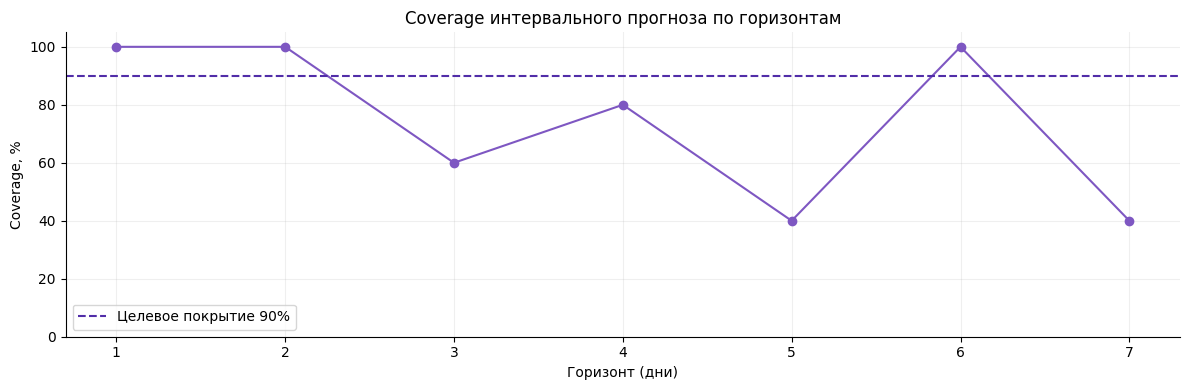

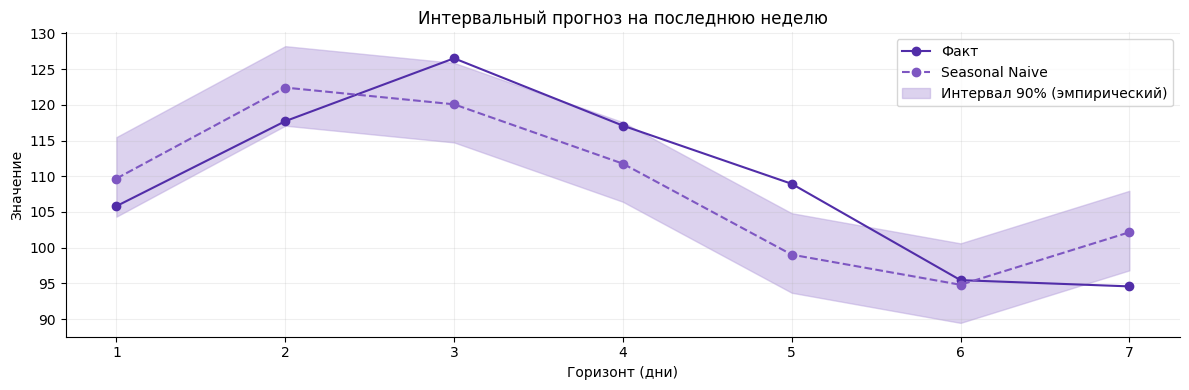

In [8]:
sn = expanding_forecasts[expanding_forecasts["Модель"] == "Seasonal Naive"].copy()
sn["Ошибка"] = sn["Факт"] - sn["Прогноз"]
calibration = sn[sn["Шаг"] <= 5]
evaluation = sn[sn["Шаг"] > 5].copy()

lower_error, upper_error = np.quantile(calibration["Ошибка"], [0.05, 0.95])
evaluation["Нижняя"] = evaluation["Прогноз"] + lower_error
evaluation["Верхняя"] = evaluation["Прогноз"] + upper_error
evaluation["Попадание"] = ((evaluation["Факт"] >= evaluation["Нижняя"]) &
                           (evaluation["Факт"] <= evaluation["Верхняя"]))
evaluation["Ширина"] = evaluation["Верхняя"] - evaluation["Нижняя"]

intervals_by_h = (evaluation.groupby("Горизонт")[["Попадание", "Ширина"]]
                  .mean().rename(columns={"Попадание": "Coverage", "Ширина": "Width"}))
intervals_by_h["Coverage, %"] = intervals_by_h["Coverage"] * 100
intervals_by_h.to_csv("interval_coverage.csv")
print(intervals_by_h.round(3).to_string())
print("Общее покрытие: {:.1f}%".format(100 * evaluation["Попадание"].mean()))
print("Средняя ширина: {:.3f}".format(evaluation["Ширина"].mean()))

plt.plot(intervals_by_h.index, intervals_by_h["Coverage, %"], "o-", color=PURPLE)
plt.axhline(90, color=DARK, linestyle="--", label="Целевое покрытие 90%")
plt.ylim(0, 105)
plt.xticks(range(1, 8))
plt.title("Coverage интервального прогноза по горизонтам")
plt.xlabel("Горизонт (дни)")
plt.ylabel("Coverage, %")
plt.legend()
save_plot(5)

# Иллюстрация интервала на последней тестовой неделе
last = evaluation[evaluation["Шаг"] == 10].sort_values("Горизонт")
x = last["Горизонт"].to_numpy()
plt.plot(x, last["Факт"], "o-", color=DARK, label="Факт")
plt.plot(x, last["Прогноз"], "o--", color=PURPLE, label="Seasonal Naive")
plt.fill_between(x, last["Нижняя"], last["Верхняя"], color=LILAC, alpha=0.45,
                 label="Интервал 90% (эмпирический)")
plt.xticks(range(1, 8))
plt.title("Интервальный прогноз на последнюю неделю")
plt.xlabel("Горизонт (дни)")
plt.ylabel("Значение")
plt.legend()
save_plot(6)

## 9. Почему нельзя случайно перемешивать временной ряд?

Сначала оценим **корректный прогноз на один день вперёд**: в каждой точке используем последнее известное значение *только из прошлого*. Затем специально построим **некорректную демонстрацию**: случайно выберем тестовые даты и оценим их через среднее ближайших известных соседей с обеих сторон. Один из соседей будет находиться **в будущем относительно тестовой даты**

                                Эксперимент   MAE  Тестовых точек
         Корректный прогноз: только прошлое 6.077              25
Некорректно: перемешивание и будущие соседи 3.046              25


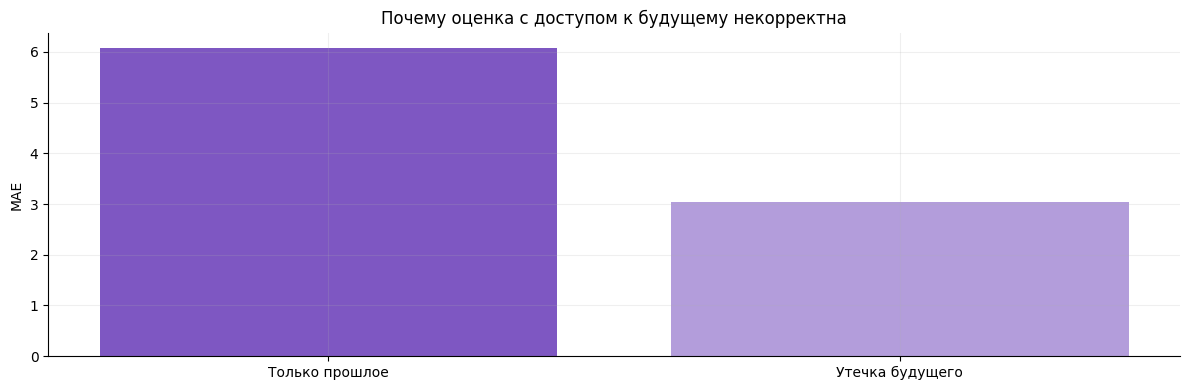

In [9]:
# Для честного сравнения используем одни и те же тестовые даты
values = daily.to_numpy()

# Случайно выбираем даты внутри второй половины ряда (не затрагивая край)
rng_bad = np.random.default_rng(7)
test_positions = np.sort(rng_bad.choice(np.arange(70, 133), size=25, replace=False))

# Корректный прогноз: на один день вперёд, известен только вчерашний факт
correct_actual = values[test_positions]
correct_predict = values[test_positions - 1]
correct_mae = np.mean(np.abs(correct_actual - correct_predict))

# Некорректный подход: случайно скрываем эти даты и берём ближайшие
# известные значения ТОГО ЖЕ ДНЯ НЕДЕЛИ до и после тестовой даты
# Последнее значение находится в будущем, значит, для реального прогноза оно недоступно
known = np.ones(len(values), dtype=bool)
known[test_positions] = False
wrong_predict = []
for pos in test_positions:
    past = [j for j in range(pos - S, -1, -S) if known[j]]
    future = [j for j in range(pos + S, len(values), S) if known[j]]
    wrong_predict.append((values[past[0]] + values[future[0]]) / 2)
wrong_predict = np.asarray(wrong_predict)
wrong_actual = values[test_positions]
wrong_mae = np.mean(np.abs(wrong_actual - wrong_predict))

leakage_table = pd.DataFrame({
    "Эксперимент": ["Корректный прогноз: только прошлое",
                    "Некорректно: перемешивание и будущие соседи"],
    "MAE": [correct_mae, wrong_mae],
    "Тестовых точек": [len(correct_actual), len(wrong_actual)]
})
leakage_table.to_csv("leakage_demo.csv", index=False)
print(leakage_table.round(3).to_string(index=False))

plt.bar(["Только прошлое", "Утечка будущего"],
        [correct_mae, wrong_mae], color=[PURPLE, LILAC])
plt.ylabel("MAE")
plt.title("Почему оценка с доступом к будущему некорректна")
save_plot(7)

## 10. Итоговые выводы

В ходе лабораторной работы были исследованы пять baseline-моделей на синтетическом ряду с недельной сезонностью. Для генерации исходных пятиминутных данных использована функция из лабораторной работы № 1, затем ряд преобразован в дневной. Прогнозирование проводилось на горизонте **7 суток**

1. **Сравнение базовых методов.** При expanding window наименьшую среднюю MASE показал **Theta (0,9998)**, а при sliding window - **Seasonal Naive (1,1427)**. Выбор лучшей модели зависит от длины обучающей истории. Theta использует более длительную историю и лучше справился в expanding-схеме, тогда как Seasonal Naive устойчиво повторял недельные колебания

2. **Сравнение метрик.** В expanding-схеме у Theta также минимальны MAE (**2,5472**) и RMSE (**2,9703**). В sliding-схеме наименьшая MAE у Seasonal Naive (**3,0166**). В исследуемом эксперименте MAE, RMSE и MASE согласуются в выборе лучшей модели в пределах каждой схемы. MAPE здесь применима, поскольку фактические значения положительны и не близки к нулю

3. **Стабильность валидации.** Для Theta стандартное отклонение MAE между десятью тестовыми неделями составило **0,427** при expanding и **1,597** при sliding. Это говорит о более устойчивой оценке ошибок Theta при расширяющейся истории в нашем эксперименте. Нельзя делать общий вывод, что expanding всегда лучше: в меняющихся процессах sliding может быть полезнее

4. **Интервальные прогнозы.** Для Seasonal Naive построен учебный интервал на основе квантилей ошибок первых пяти шагов. На последних пяти тестовых неделях общее фактическое покрытие составило **74.3%**, а средняя ширина интервала - **11.13**. Покрытие оказалось ниже заявленного уровня 90%, поэтому интервалу не хватает надёжной калибровки. Для улучшения понадобятся дополнительные исторические данные или отдельные интервалы по горизонтам

5. **Проверка утечки данных.** Корректный однодневный прогноз по прошлому на выбранных датах дал MAE **6,077**. Некорректное восстановление тех же дат с использованием будущих значений показало искусственно улучшенную MAE **3,046**. Это **не сопоставимые по доступной информации прогнозы**: второй способ нельзя использовать при реальном прогнозировании. Пример показывает риск завышения качества из-за утечки

**Общий вывод.** Для сравнения моделей временных рядов недостаточно одной метрики или одного разбиения. Нужно проверять несколько baseline-моделей на одинаковых временных окнах, сравнивать MAE, RMSE, MASE и контролировать отсутствие информации из будущего. В данном исследовании наиболее успешной моделью оказалась **Theta при expanding** и **Seasonal Naive при sliding**, а интервальные прогнозы потребовали дополнительной калибровки
